<a href="https://colab.research.google.com/github/nachopedretti/diploup2026-TP2/blob/main/notebooks/05_validacion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TP2 — Validación del modelo

Evaluar el modelo guardado en **Train y Test**.

In [5]:
import joblib
import urllib.request
from pathlib import Path

# Descargar el modelo desde GitHub
url = "https://raw.githubusercontent.com/nachopedretti/diploup2026-TP2/main/models/regresion_logistica_balanceada.pkl"

ruta_modelos = Path("/content/models")
ruta_modelos.mkdir(parents=True, exist_ok=True)

ruta_modelo = ruta_modelos / "regresion_logistica_balanceada.pkl"

urllib.request.urlretrieve(url, ruta_modelo)

# Cargar modelo y umbral
modelo_guardado = joblib.load(ruta_modelo)

modelo_final = modelo_guardado["modelo"]
umbral_final = modelo_guardado["umbral"]

print("Modelo cargado:", type(modelo_final).__name__)
print("Umbral de clasificación:", umbral_final)


Modelo cargado: LogisticRegression
Umbral de clasificación: 0.55


## Predicciones y reportes Train/Test

In [6]:

import joblib
import urllib.request
from pathlib import Path

# Carpeta local de modelos
ruta_modelos = Path("/content/models")
ruta_modelos.mkdir(parents=True, exist_ok=True)

# Modelos disponibles en GitHub
archivos_rf = [
    "random_forest_regularizado.pkl",
    "random_forest_regularizado_v2.pkl",
    "random_forest_regularizado_v3.pkl",
    "random_forest_final.pkl"
]

base_url = "https://raw.githubusercontent.com/nachopedretti/diploup2026-TP2/main/models/"

for archivo in archivos_rf:
    ruta_archivo = ruta_modelos / archivo

    # Descargar desde GitHub
    urllib.request.urlretrieve(base_url + archivo, ruta_archivo)

    # Cargar modelo
    objeto = joblib.load(ruta_archivo)

    modelo = objeto["modelo"] if isinstance(objeto, dict) and "modelo" in objeto else objeto

    print(f"\n{archivo}")
    print("Tipo:", type(modelo).__name__)

    if hasattr(modelo, "get_params"):
        parametros = modelo.get_params()

        for parametro in [
            "n_estimators",
            "max_depth",
            "min_samples_split",
            "min_samples_leaf",
            "max_features",
            "class_weight"
        ]:
            print(f"{parametro}: {parametros.get(parametro)}")


random_forest_regularizado.pkl
Tipo: RandomForestClassifier
n_estimators: 150
max_depth: 10
min_samples_split: 2
min_samples_leaf: 2
max_features: sqrt
class_weight: None

random_forest_regularizado_v2.pkl
Tipo: RandomForestClassifier
n_estimators: 150
max_depth: 8
min_samples_split: 2
min_samples_leaf: 5
max_features: sqrt
class_weight: None

random_forest_regularizado_v3.pkl
Tipo: RandomForestClassifier
n_estimators: 150
max_depth: 8
min_samples_split: 2
min_samples_leaf: 5
max_features: 0.5
class_weight: None

random_forest_final.pkl
Tipo: RandomForestClassifier
n_estimators: 100
max_depth: 10
min_samples_split: 2
min_samples_leaf: 5
max_features: sqrt
class_weight: None


In [7]:
import pandas as pd

base_url = "https://raw.githubusercontent.com/nachopedretti/diploup2026-TP2/main/data/processed/"

# Cargar Train y Test
X_train = pd.read_csv(base_url + "X_train.csv")
X_test = pd.read_csv(base_url + "X_test.csv")

y_train = pd.read_csv(base_url + "y_train.csv").squeeze("columns")
y_test = pd.read_csv(base_url + "y_test.csv").squeeze("columns")

# Verificar dimensiones
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)


X_train: (40000, 24)
X_test: (10000, 24)
y_train: (40000,)
y_test: (10000,)


In [8]:
from sklearn.metrics import classification_report

prob_train = modelo_final.predict_proba(X_train)[:, 1]
y_pred_train = (prob_train >= umbral_final).astype(int)

prob_test = modelo_final.predict_proba(X_test)[:, 1]
y_pred_test = (prob_test >= umbral_final).astype(int)

print("TRAIN")
print(classification_report(y_train, y_pred_train))

print("-" * 55)

print("TEST")
print(classification_report(y_test, y_pred_test))

TRAIN
              precision    recall  f1-score   support

           0       0.91      0.62      0.74     25337
           1       0.58      0.90      0.70     14663

    accuracy                           0.72     40000
   macro avg       0.74      0.76      0.72     40000
weighted avg       0.79      0.72      0.73     40000

-------------------------------------------------------
TEST
              precision    recall  f1-score   support

           0       0.92      0.62      0.74      6334
           1       0.58      0.90      0.71      3666

    accuracy                           0.72     10000
   macro avg       0.75      0.76      0.72     10000
weighted avg       0.79      0.72      0.73     10000



In [9]:

print("Modelo utilizado:", type(modelo_final).__name__)
print("Umbral utilizado:", umbral_final)

probabilidades_test = modelo_final.predict_proba(X_test)[:, 1]
predicciones_test = (probabilidades_test >= umbral_final).astype(int)

from sklearn.metrics import classification_report

print("\nResultados sobre Test:")
print(classification_report(y_test, predicciones_test))

Modelo utilizado: LogisticRegression
Umbral utilizado: 0.55

Resultados sobre Test:
              precision    recall  f1-score   support

           0       0.92      0.62      0.74      6334
           1       0.58      0.90      0.71      3666

    accuracy                           0.72     10000
   macro avg       0.75      0.76      0.72     10000
weighted avg       0.79      0.72      0.73     10000



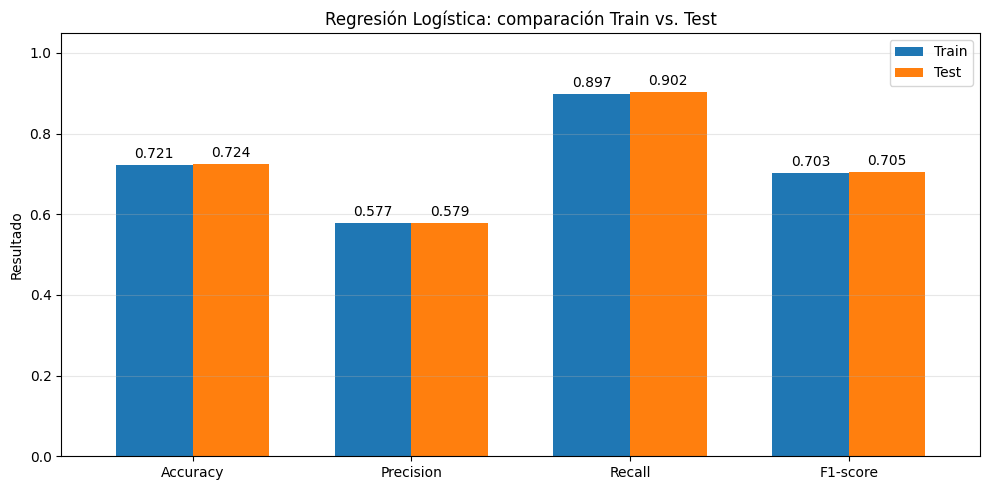

  Métrica  Train   Test
 Accuracy 0.7214 0.7236
Precision 0.5772 0.5789
   Recall 0.8974 0.9023
 F1-score 0.7026 0.7053


In [10]:
import matplotlib.pyplot as plt
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score)

# Calcular métricas de Train y Test
metricas = pd.DataFrame({
    "Métrica": ["Accuracy", "Precision", "Recall", "F1-score"],
    "Train": [
        accuracy_score(y_train, y_pred_train),
        precision_score(y_train, y_pred_train),
        recall_score(y_train, y_pred_train),
        f1_score(y_train, y_pred_train)],
    "Test": [
        accuracy_score(y_test, y_pred_test),
        precision_score(y_test, y_pred_test),
        recall_score(y_test, y_pred_test),
        f1_score(y_test, y_pred_test)]})

# Graficar
ax = metricas.set_index("Métrica").plot(
    kind="bar",
    figsize=(10, 5),
    rot=0,
    width=0.7
)

plt.title("Regresión Logística: comparación Train vs. Test")
plt.xlabel("")
plt.ylabel("Resultado")
plt.ylim(0, 1.05)
plt.grid(axis="y", alpha=0.3)
plt.legend()

# Mostrar valores sobre las barras
for contenedor in ax.containers:
    ax.bar_label(contenedor, fmt="%.3f", padding=3)

plt.tight_layout()
plt.show()

# Mostrar tabla de resultados
print(metricas.round(4).to_string(index=False))

In [11]:
##Comparar Train y Test

In [12]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

resultados_modelos = []

# Comparar todas las versiones de Random Forest
for archivo in archivos_rf:
    objeto = joblib.load(ruta_modelos / archivo)
    modelo = objeto["modelo"] if isinstance(objeto, dict) else objeto

    for conjunto, X, y in [
        ("Train", X_train, y_train),
        ("Test", X_test, y_test)
    ]:
        predicciones = modelo.predict(X)

        resultados_modelos.append({
            "Modelo": archivo.replace(".pkl", ""),
            "Conjunto": conjunto,
            "Accuracy": accuracy_score(y, predicciones),
            "Precision": precision_score(y, predicciones),
            "Recall": recall_score(y, predicciones),
            "F1-score": f1_score(y, predicciones)
        })

# Agregar Regresión Logística definitiva (umbral 0.55)
for conjunto, X, y in [
    ("Train", X_train, y_train),
    ("Test", X_test, y_test)]:
    probabilidades = modelo_final.predict_proba(X)[:, 1]
    predicciones = (probabilidades >= umbral_final).astype(int)

    resultados_modelos.append({
        "Modelo": "regresion_logistica_balanceada",
        "Conjunto": conjunto,
        "Accuracy": accuracy_score(y, predicciones),
        "Precision": precision_score(y, predicciones),
        "Recall": recall_score(y, predicciones),
        "F1-score": f1_score(y, predicciones)})

comparacion_modelos = pd.DataFrame(resultados_modelos)

# Mostrar F1-score en Train y Test y su diferencia
tabla_f1 = comparacion_modelos.pivot(
    index="Modelo",
    columns="Conjunto",
    values="F1-score")

tabla_f1["Diferencia Train - Test"] = tabla_f1["Train"] - tabla_f1["Test"]

display(tabla_f1.round(4))

Conjunto,Test,Train,Diferencia Train - Test
Modelo,,,
random_forest_final,0.6904,0.7531,0.0627
random_forest_regularizado,0.6965,0.7656,0.0692
random_forest_regularizado_v2,0.6843,0.7169,0.0326
random_forest_regularizado_v3,0.6885,0.7218,0.0333
regresion_logistica_balanceada,0.7053,0.7026,-0.0028


# Comparación del F1-score entre Train y Test


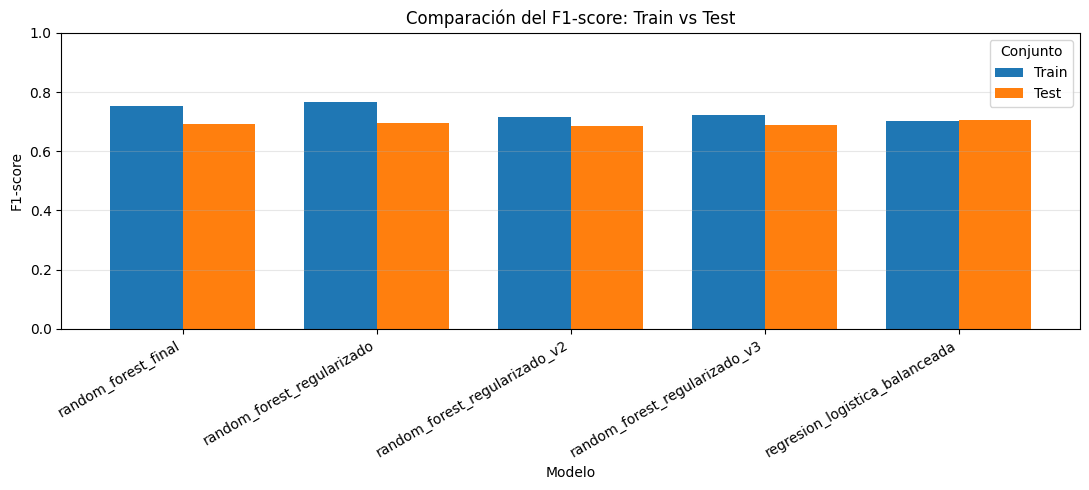

In [13]:
import matplotlib.pyplot as plt

tabla_grafico = comparacion_modelos.pivot(
    index="Modelo",
    columns="Conjunto",
    values="F1-score"
)

ax = tabla_grafico[["Train", "Test"]].plot(
    kind="bar",
    figsize=(11, 5),
    width=0.75
)

plt.title("Comparación del F1-score: Train vs Test")
plt.xlabel("Modelo")
plt.ylabel("F1-score")
plt.ylim(0, 1)
plt.xticks(rotation=30, ha="right")
plt.legend(title="Conjunto")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

Random Forest original: presenta la mayor diferencia entre Train y Test, evidenciando un sobreajuste importante.

Random Forest regularizados: reducen esa diferencia, aunque también disminuye el F1-score en Test.

Regresión Logística: muestra resultados prácticamente iguales en ambos conjuntos, siendo el modelo con menor diferencia entre Train y Test.

In [14]:
# Predicciones de la Regresión Logística con umbral 0.55
pred_test = (
    modelo_final.predict_proba(X_test)[:, 1] >= 0.55
).astype(int)

In [15]:
from sklearn.metrics import recall_score, f1_score
import pandas as pd

# Evaluación del modelo final por género
resultados_genero = []

for genero, nombre in [(0, "Mujeres"), (1, "Hombres")]:
    filtro = X_test["gender"] == genero

    y_real = y_test[filtro]
    y_pred = pred_test[filtro]

    resultados_genero.append({
        "Género": nombre,
        "Fumadores reales": (y_real == 1).sum(),
        "Recall fumadores (%)": round(
            recall_score(y_real, y_pred, zero_division=0) * 100, 2
        ),
        "F1-score fumadores (%)": round(
            f1_score(y_real, y_pred, zero_division=0) * 100, 2)})

tabla_genero = pd.DataFrame(resultados_genero)

display(tabla_genero)

,Género,Fumadores reales,Recall fumadores (%),F1-score fumadores (%)
0,Mujeres,144,0.00,0.00
1,Hombres,3522,93.92,71.63


### Conclusiones

Evaluamos la **Regresión Logística balanceada** con umbral **0.55**, comparando Train (40.000) y Test (10.000).

- **Accuracy:** cerca del 72% en ambos conjuntos.
- **Recall:** aproximadamente 90%, identificando 9 de cada 10 fumadores.
- **Precision:** cerca del 58%, con falsos positivos.
- **F1-score:** alrededor de 0.70, con resultados similares entre Train y Test.

También comparamos con Random Forest:

- **Random Forest original:** tuvo overfitting, con F1 de 0.9944 en Train y 0.7347 en Test.
- **Random Forest regularizados:** redujeron el overfitting, pero también bajó el F1 en Test.
- **Regresión Logística:** mantuvo un F1 similar entre Train (0.7026) y Test (0.7053).

**Análisis por género**

Revisamos las predicciones por género y encontramos una diferencia importante. El modelo no detectó ninguna de las 144 mujeres fumadoras del Test, mientras que en hombres tuvo un Recall del 93,92%.

En los datos originales solo el 4,3% de las mujeres fuma, contra el 55,2% de los hombres. Vimos que el género tiene bastante peso entre las 24 variables utilizadas.

**Decisión final**

Mantenemos la Regresión Logística balanceada con umbral 0.55 por su estabilidad entre Train y Test y menor overfitting que Random Forest.

El modelo tiene una limitación importante para identificar mujeres fumadoras y le da mucho peso al género en la predicción. pensé en eliminar esta variable, pero finalmente decidí mantenerla, ya que en la base original las mujeres tienen una menor proporción de fumadoras.